# 과제 3 — ACT chunk_size 비교 실험

**과제 내용**: 같은 데이터셋으로 `chunk_size`만 10, 50, 100으로 바꾼 ACT 정책 3개를 학습하고, 실제 로봇에서 각각 10회씩 평가해 chunk_size가 성공률·동작의 부드러움·반응성에 주는 영향을 분석한다. chunk_size=100 정책에는 temporal ensemble을 적용해 10회 더 평가하고 결과를 비교한다. 학습된 정책 3개는 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1, 2와 같은 저장소, assignments 폴더)에 `assignment_3.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 이번 과제는 **통제 실험**이다. 실험할 ACT 정책 3개는 `chunk_size`와 `n_action_steps`를 제외한 모든 설정(데이터셋, steps, batch_size, seed)이 같아야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 과제 2의 정책(기본값 chunk_size=100)을 chunk_size=100 조건으로 **재사용해도 된다.** 이 경우 나머지 두 정책은 과제 2와 같은 데이터셋·steps·batch_size·seed로 학습해야 한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [55]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2021136100"
NAME = "이준"
HF_USER = "LeeJun12"

TASK = "Pick up the cube and put it in the box."   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/pick-cube-2cam_20261028_193431"   # 세 정책이 공통으로 사용한 학습 데이터셋
CHUNK_SIZES = [10, 50, 100]

# 정책 repo (chunk100은 과제 2 정책 재사용)
POLICY_REPOS = {
    10:  f"{HF_USER}/act_pick-cube-2cam_chunk10",
    50:  f"{HF_USER}/act_pick-cube-2cam_chunk50",
    100: f"{HF_USER}/act_pick-cube-2cam",
}

# 평가 데이터셋 — lerobot-rollout으로 녹화, 이름은 rollout_로 시작하고 끝에 녹화 시각이 붙는다.
# Hub에 실제로 올라간 이름을 조건별로 그대로 적을 것
EVAL_DATASETS = {
    10:  f"{HF_USER}/rollout_act_pick-cube-2cam_chunk10_20261113_102939",    # [평가 후 수정]
    50:  f"{HF_USER}/rollout_act_pick-cube-2cam_chunk50_20261113_105030",    # [평가 후 수정]
    100: f"{HF_USER}/rollout_act_pick-cube-2cam_chunk100_20261113_110558",   # [평가 후 수정]
}
WANDB_URL = "https://wandb.ai/leejun12-korea-university-of-technology-and-education/lerobot"   # 세 run이 있는 프로젝트

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
for k in CHUNK_SIZES:
    print(f"chunk{k:<4} 정책 :", f"https://huggingface.co/{POLICY_REPOS[k]}")
    print(f"chunk{k:<4} 평가 :", f"https://huggingface.co/datasets/{EVAL_DATASETS[k]}")
print("wandb         :", WANDB_URL or "(미사용)")

학번/이름     : 2021136100 이준
태스크        : Pick up the cube and put it in the box.
학습 데이터셋 : https://huggingface.co/datasets/LeeJun12/pick-cube-2cam_20261028_193431
chunk10   정책 : https://huggingface.co/LeeJun12/act_pick-cube-2cam_chunk10
chunk10   평가 : https://huggingface.co/datasets/LeeJun12/rollout_act_pick-cube-2cam_chunk10_20261113_102939
chunk50   정책 : https://huggingface.co/LeeJun12/act_pick-cube-2cam_chunk50
chunk50   평가 : https://huggingface.co/datasets/LeeJun12/rollout_act_pick-cube-2cam_chunk50_20261113_105030
chunk100  정책 : https://huggingface.co/LeeJun12/act_pick-cube-2cam
chunk100  평가 : https://huggingface.co/datasets/LeeJun12/rollout_act_pick-cube-2cam_chunk100_20261113_110558
wandb         : https://wandb.ai/leejun12-korea-university-of-technology-and-education/lerobot


In [56]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.2
버전 확인   : 통과


In [57]:
# Hub 접근 확인 — 7개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset")]
checks += [(POLICY_REPOS[k], "model") for k in CHUNK_SIZES]
checks += [(EVAL_DATASETS[k], "dataset") for k in CHUNK_SIZES]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] LeeJun12/pick-cube-2cam_20261028_193431  (파일 10개)
OK   [model  ] LeeJun12/act_pick-cube-2cam_chunk10  (파일 9개)
OK   [model  ] LeeJun12/act_pick-cube-2cam_chunk50  (파일 9개)
OK   [model  ] LeeJun12/act_pick-cube-2cam  (파일 9개)
OK   [dataset] LeeJun12/rollout_act_pick-cube-2cam_chunk10_20261113_102939  (파일 9개)
OK   [dataset] LeeJun12/rollout_act_pick-cube-2cam_chunk50_20261113_105030  (파일 9개)
OK   [dataset] LeeJun12/rollout_act_pick-cube-2cam_chunk100_20261113_110558  (파일 9개)


## 1. 실험 설계

### 1-1. 배경
`chunk_size`(k)는 ACT가 한 번의 추론으로 예측하는 미래 행동의 개수다. 이번 실험에서는 `n_action_steps = chunk_size`로 두어 **예측한 청크를 끝까지 실행한 뒤 다시 추론**한다. (temporal ensemble은 5절에서 따로 진행하기 때문에 이 실험에는 사용하지 않는다.)

청크의 초 단위 길이는 데이터셋의 fps에 따라 달라진다.

$$T_{\text{chunk}} = \frac{\text{chunk\_size}}{\text{fps}}$$

- chunk_size가 **크면**: 결정 횟수가 줄어 오차 누적(compounding error)이 줄지만, 청크를 실행하는 동안 새 관측을 반영하지 못해 상황 변화에 둔감해진다.
- chunk_size가 **작으면**: 자주 새로 관측해 반응성은 좋지만, 단일 스텝 정책에 가까워져 오차 누적과 청크 경계의 덜컥거림이 늘 수 있다.

In [59]:
# 학습 데이터셋의 fps와 에피소드 길이로 청크 길이 환산
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

train_info = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
if train_info:
    fps = train_info["fps"]
    ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
    print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f} s\n")
    for k in CHUNK_SIZES:
        print(f"chunk_size={k:>3d} -> {k/fps:5.2f} s  (평균 에피소드의 {k/fps/ep_len_s*100:4.1f}%)")

fps: 30, 에피소드 수: 50, 평균 에피소드 길이: 10.0 s

chunk_size= 10 ->  0.33 s  (평균 에피소드의  3.3%)
chunk_size= 50 ->  1.67 s  (평균 에피소드의 16.7%)
chunk_size=100 ->  3.33 s  (평균 에피소드의 33.3%)


### 1-2. 가설 (학습 전에 작성)
`[작성]` 결과가 가설과 달라도 감점하지 않는다. 왜 달랐는지를 4절에서 분석하는 것이 더 중요하다.

- 성공률이 가장 높을 것으로 예상하는 조건과 이유: **chunk_size=50**을 예상한다. 30fps에서 50스텝은 약 1.7초로, 평균 10초인 에피소드를 약 6번의 결정으로 끝낸다. chunk10(약 0.33초)은 에피소드당 약 30번 새로 예측해야 해서 작은 예측 오차가 매번 쌓이는 compounding error가 커질 것이고, chunk100(약 3.3초)은 에피소드의 3분의 1을 한 번에 예측하므로 실행 도중 위치가 조금 어긋나도 보정하지 못할 것이다. 과제 2에서 chunk100 정책이 큐브가 먼 위치일 때 파지를 빗겨 실패한 것도 이 한계로 보인다. 50은 오차 누적과 반응성 사이의 절충점이라고 생각한다.
- 동작이 가장 부드러울 것으로 예상하는 조건과 이유: **chunk_size=100**을 예상한다. 한 청크 안에서는 정책이 예측한 연속 궤적을 그대로 따르고, 청크가 바뀌는 횟수도 에피소드당 3번 정도뿐이다. 반대로 chunk10은 0.33초마다 새로 예측하므로 청크 경계에서 목표가 바뀌며 떨리거나 머뭇거릴 것으로 예상한다.
- 물체가 중간에 움직였을 때 가장 잘 따라갈 것으로 예상하는 조건과 이유: **chunk_size=10**을 예상한다. 0.33초마다 새 관측을 반영해 다시 예측하므로 물체가 옮겨져도 곧바로 경로를 바꿀 수 있다. chunk100은 한 번 예측한 약 3.3초 동안 새 관측을 반영하지 못해 옮겨진 물체를 놓칠 가능성이 가장 크다.

### 1-3. 통제 변수 확인
아래 셀은 업로드된 세 정책의 설정을 비교한다. `chunk_size`와 `n_action_steps` 외에 다른 값이 있으면 [불일치]로 표시된다.

In [62]:
import pandas as pd

rows = []
for k in CHUNK_SIZES:
    pc = load_json(POLICY_REPOS[k], "config.json") or {}
    tc = load_json(POLICY_REPOS[k], "train_config.json") or {}
    rows.append({
        "condition": f"chunk{k}",
        "chunk_size": pc.get("chunk_size"),
        "n_action_steps": pc.get("n_action_steps"),
        "kl_weight": pc.get("kl_weight"),
        "dataset": tc.get("dataset", {}).get("repo_id"),
        "steps": tc.get("steps"),
        "batch_size": tc.get("batch_size"),
        "seed": tc.get("seed"),
    })
cfg_df = pd.DataFrame(rows).set_index("condition")
display(cfg_df)

for col in ["kl_weight", "dataset", "steps", "batch_size", "seed"]:
    same = cfg_df[col].nunique(dropna=False) == 1
    print(("[일치]   " if same else "[불일치] ") + col)
for k in CHUNK_SIZES:
    r = cfg_df.loc[f"chunk{k}"]
    ok = r["chunk_size"] == k and r["n_action_steps"] == k
    print(("[일치]   " if ok else "[불일치] ") + f"chunk{k}: chunk_size={r['chunk_size']}, n_action_steps={r['n_action_steps']}")

,chunk_size,n_action_steps,kl_weight,dataset,steps,batch_size,seed
condition,,,,,,,
chunk10,10,10,10.0,LeeJun12/pick-cube-2cam_20261028_193431,50000,8,1000
chunk50,50,50,10.0,LeeJun12/pick-cube-2cam_20261028_193431,50000,8,1000
chunk100,100,100,10.0,LeeJun12/pick-cube-2cam_20261028_193431,50000,8,1000


[일치]   kl_weight
[일치]   dataset
[일치]   steps
[일치]   batch_size
[일치]   seed
[일치]   chunk10: chunk_size=10, n_action_steps=10
[일치]   chunk50: chunk_size=50, n_action_steps=50
[일치]   chunk100: chunk_size=100, n_action_steps=100


## 2. 학습

### 2-1. 실행한 학습 명령어
`[작성]` 실제로 실행한 `lerobot-train` 명령어 3개를 아래 코드 블록에 붙여 넣는다. 과제 2 정책을 재사용했다면 chunk100 자리에 "과제 2 정책 재사용"과 repo_id를 적는다.

```bash
# chunk_size = 10
lerobot-train \
  --dataset.repo_id=LeeJun12/pick-cube-2cam_20261028_193431 \
  --dataset.video_backend=pyav \
  --policy.type=act \
  --policy.chunk_size=10 --policy.n_action_steps=10 \
  --policy.device=cuda \
  --policy.repo_id=LeeJun12/act_pick-cube-2cam_chunk10 \
  --policy.private=false \
  --output_dir=/home/work/RobotAI/outputs/train/act_pick-cube-2cam_chunk10 \
  --job_name=act_pick-cube-2cam_chunk10 \
  --batch_size=8 --steps=50000 --seed=1000 --save_freq=10000 --log_freq=200 \
  --num_workers=2 \
  --wandb.enable=true --wandb.disable_artifact=true

# chunk_size = 50
lerobot-train \
  --dataset.repo_id=LeeJun12/pick-cube-2cam_20261028_193431 \
  --dataset.video_backend=pyav \
  --policy.type=act \
  --policy.chunk_size=50 --policy.n_action_steps=50 \
  --policy.device=cuda \
  --policy.repo_id=LeeJun12/act_pick-cube-2cam_chunk50 \
  --policy.private=false \
  --output_dir=/home/work/RobotAI/outputs/train/act_pick-cube-2cam_chunk50 \
  --job_name=act_pick-cube-2cam_chunk50 \
  --batch_size=8 --steps=50000 --seed=1000 --save_freq=10000 --log_freq=200 \
  --num_workers=2 \
  --wandb.enable=true --wandb.disable_artifact=true

# chunk_size = 100 — 과제 2 정책 재사용 (LeeJun12/act_pick-cube-2cam)
# chunk_size, n_action_steps는 ACT 기본값(100, 100), seed는 기본값(1000)을 사용
lerobot-train \
  --dataset.repo_id=LeeJun12/pick-cube-2cam_20261028_193431 \
  --policy.type=act \
  --policy.device=cuda \
  --policy.repo_id=LeeJun12/act_pick-cube-2cam \
  --policy.private=false \
  --output_dir=/home/work/RobotAI/outputs/train/act_pick-cube-2cam \
  --job_name=act_pick-cube-2cam \
  --batch_size=8 --steps=100000 --save_freq=10000 --log_freq=200 \
  --num_workers=2 \
  --wandb.enable=true --wandb.disable_artifact=true

# 20,000 스텝 체크포인트에서 steps를 50,000으로 줄여 이어서 학습
lerobot-train \
  --config_path=/home/work/RobotAI/outputs/train/act_pick-cube-2cam/checkpoints/last/pretrained_model/train_config.json \
  --resume=true --steps=50000
```

> 참고 (0.6.0): `--policy.repo_id`를 주면 학습 후 정책이 Hub에 자동 업로드된다. 학습 기본값은 `steps=100000`, `batch_size=8`, `seed=1000`이다. 세 조건을 같은 값으로 맞추려면 기본값을 쓰더라도 명령어에 명시해 두는 편이 안전하다.

### 2-2. 학습 환경
`[작성]`
- GPU: chunk10, chunk50은 Backend.AI 서버의 CUDA GPU(35,943 MiB), chunk100(과제 2 정책)은 같은 서버의 CUDA GPU(21,566 MiB)에서 학습했다.
- 학습 step 수 (세 조건 공통): 50,000
- 조건별 소요 시간 (chunk10 / chunk50 / chunk100): 약 3시간 55분 / 약 4시간 2분 / 1시간 15분
- 참고 사항:
  - 서버의 PyTorch(NGC 빌드 2.11)와 torchcodec이 호환되지 않아, chunk10과 chunk50은 `--dataset.video_backend=pyav`로 영상을 읽었다. 같은 영상의 같은 프레임을 읽으므로 학습 데이터는 동일하다.
  - 시간을 줄이기 위해 chunk10과 chunk50은 같은 GPU에서 동시에 학습했다. 이 때문에 각 학습 속도가 단독 실행(약 6 step/s)보다 느렸고(약 3.3 step/s), 과제 2보다 소요 시간이 길다. 학습 결과에는 영향이 없다.
  - chunk100은 과제 2에서 100,000스텝으로 시작해 20,000스텝에서 50,000스텝으로 줄여 이어 학습했다. 학습률이 1e-5로 고정(스케줄러 없음)이라 최종 학습 조건은 다른 두 정책과 같다.
  - 세 정책 모두 데이터셋, steps, batch_size, seed와 ACT 하이퍼파라미터(kl_weight=10, lr=1e-5 등)가 같고 chunk_size와 n_action_steps만 다르다.
  - chunk10과 chunk50은 같은 GPU에서 동시에 학습해서 느려졌다. chunk_size 때문에 생긴 차이가 아니다.

### 2-3. 학습 곡선
`[작성]` 세 조건의 loss 곡선을 **한 그래프에 겹쳐** 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw3.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve_hw3.png)

In [65]:
# (선택) wandb에서 내보낸 CSV로 직접 그리기
# CSV 형식 가정: 첫 열 step, 나머지 열이 조건별 loss (열 이름은 본인 파일에 맞게 수정)
import os
import matplotlib.pyplot as plt

CSV_PATH = "images/loss_hw3.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    for col in df.columns[1:]:
        plt.plot(df.iloc[:, 0], df[col], label=col)
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss by chunk_size")
    plt.legend(); plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

CSV 없음 — 위 마크다운의 이미지로 대체


In [66]:
# [작성] 학습 종료 시점의 손실 (wandb 내보내기 CSV, 50,000 스텝 값)
# ACT는 l1_loss(행동 복원 손실)와 kld_loss(KL 항)를 따로 출력한다
final_loss = pd.DataFrame({
    "chunk_size": CHUNK_SIZES,
    "l1_loss":  [0.0497, 0.0647, 0.0731],
    "kld_loss": [0.000032, 0.000193, 0.000228],
}).set_index("chunk_size")
final_loss

,l1_loss,kld_loss
chunk_size,,
10,0.0497,0.000032
50,0.0647,0.000193
100,0.0731,0.000228


## 3. 실로봇 평가 (조건별 10회, 총 30회)

### 3-1. 평가 프로토콜
1. 테이블에 물체 시작 위치 10곳을 테이프로 표시하고 1~10번을 매긴다. **세 정책 모두 이 10곳을 같은 순서로** 사용한다. (에피소드 0 = 위치 1)
2. 조명, 카메라 위치, 로봇 시작 자세를 데이터 수집 때와 같게 맞춘다.
3. 성공 기준을 **평가 전에** 아래에 적고, 평가 도중 바꾸지 않는다.

`[작성]` 성공 기준
- 성공: 큐브를 집어 박스 안에 넣고, 그리퍼가 큐브를 놓아 큐브가 박스 안에 완전히 들어가 있는 상태
- 실패: 큐브를 못 집음, 옮기는 중 떨어뜨림, 박스 밖에 놓음, 제한 시간 초과
- 에피소드 제한 시간(초): 20

### 3-2. 평가 명령어
평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어 3개를 붙여 넣는다. (`--policy.path`, `--dataset.num_episodes=10` 포함)

```bash
# chunk_size = 10
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=LeeJun12/act_pick-cube-2cam_chunk10 \
  --robot.type=so101_follower \
  --robot.port=COM4 \
  --robot.id=my_follower_arm \
  --robot.cameras="{ wrist: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, overhead: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 30}}" \
  --dataset.repo_id=LeeJun12/rollout_act_pick-cube-2cam_chunk10 \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=20 \
  --dataset.reset_time_s=15 \
  --dataset.private=false

# chunk_size = 50
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=LeeJun12/act_pick-cube-2cam_chunk50 \
  --robot.type=so101_follower \
  --robot.port=COM4 \
  --robot.id=my_follower_arm \
  --robot.cameras="{ wrist: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, overhead: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 30}}" \
  --dataset.repo_id=LeeJun12/rollout_act_pick-cube-2cam_chunk50 \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=20 \
  --dataset.reset_time_s=15 \
  --dataset.private=false

# chunk_size = 100 (과제 2 정책 재사용)
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=LeeJun12/act_pick-cube-2cam \
  --robot.type=so101_follower \
  --robot.port=COM4 \
  --robot.id=my_follower_arm \
  --robot.cameras="{ wrist: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, overhead: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 30}}" \
  --dataset.repo_id=LeeJun12/rollout_act_pick-cube-2cam_chunk100 \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=20 \
  --dataset.reset_time_s=15 \
  --dataset.private=false

- 평가는 Windows 10 PC(CPU 추론)에서 진행했고, 실제로는 한 줄로 입력했다.
- 리더 암 없이 팔로워 암만 연결했다(`--teleop.*` 생략).
- USB 포트를 다시 연결하면서 카메라 번호가 데이터 수집 때와 바뀌었다(wrist 1→0, overhead 0→1). 정책은 카메라 이름으로 영상을 구분하므로 이름은 학습 데이터와 같게 유지했다.
```

In [68]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CHUNK_SIZES:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"chunk{k:<4} 에피소드 {n_ep}개, 프레임 {info.get('total_frames')}, fps {info.get('fps')}  ->",
              "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in EVAL_DATASETS.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f"chunk {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

chunk10   에피소드 10개, 프레임 3591, fps 30  -> 통과
chunk50   에피소드 10개, 프레임 5276, fps 30  -> 통과
chunk100  에피소드 10개, 프레임 5589, fps 30  -> 통과
chunk 10 이름 규칙: 통과
chunk 50 이름 규칙: 통과
chunk 100 이름 규칙: 통과


### 3-3. 회차별 결과
`[작성]` 아래 `results`를 실제 결과로 채운다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. (예: "큐브 위치를 놓침", "청크가 바뀌는 순간 팔이 튐", "목표 근처에서 계속 떨림")

In [70]:
def blank(): 
    return [{"episode": i, "position": i + 1, "success": None, "smooth": None, "note": ""} for i in range(10)]

F10  = "큐브 쪽으로는 따라가지만 0.33초 간격으로 끊기며 떨림. 파지 직전 위치가 어긋나 엉뚱한 곳을 집거나 그리퍼에 큐브가 걸려 밀려남"
F50  = "큐브 근처까지 접근하나 파지 위치가 어긋남. 엉뚱한 곳을 집거나 그리퍼가 큐브에 걸려 큐브가 밀려남"
F100 = "부드럽게 접근하지만 파지 직전 위치가 조금 어긋나 집다가 놓침. 한 청크(3.3초) 동안 계획을 수정하지 못함"

results = {
    10: [
        {"episode": 0, "position": 1,  "success": False, "smooth": 2, "note": F10},
        {"episode": 1, "position": 2,  "success": False, "smooth": 2, "note": F10},
        {"episode": 2, "position": 3,  "success": False, "smooth": 2, "note": F10},
        {"episode": 3, "position": 4,  "success": False, "smooth": 2, "note": F10},
        {"episode": 4, "position": 5,  "success": True,  "smooth": 2, "note": "성공했지만 이동 내내 떨림과 끊김이 남아 있음"},
        {"episode": 5, "position": 6,  "success": False, "smooth": 2, "note": F10},
        {"episode": 6, "position": 7,  "success": False, "smooth": 2, "note": F10},
        {"episode": 7, "position": 8,  "success": False, "smooth": 2, "note": F10},
        {"episode": 8, "position": 9,  "success": False, "smooth": 2, "note": F10},
        {"episode": 9, "position": 10, "success": False, "smooth": 2, "note": F10},
    ],
    50: [
        {"episode": 0, "position": 1,  "success": False, "smooth": 3, "note": F50},
        {"episode": 1, "position": 2,  "success": False, "smooth": 3, "note": F50},
        {"episode": 2, "position": 3,  "success": False, "smooth": 3, "note": F50},
        {"episode": 3, "position": 4,  "success": False, "smooth": 3, "note": F50},
        {"episode": 4, "position": 5,  "success": True,  "smooth": 3, "note": "성공"},
        {"episode": 5, "position": 6,  "success": True,  "smooth": 3, "note": "성공"},
        {"episode": 6, "position": 7,  "success": True,  "smooth": 3, "note": "성공"},
        {"episode": 7, "position": 8,  "success": True,  "smooth": 3, "note": "성공"},
        {"episode": 8, "position": 9,  "success": False, "smooth": 3, "note": F50},
        {"episode": 9, "position": 10, "success": True,  "smooth": 3, "note": "성공"},
    ],
    100: [
        {"episode": 0, "position": 1,  "success": True,  "smooth": 4, "note": "성공, 부드럽게 이동"},
        {"episode": 1, "position": 2,  "success": True,  "smooth": 4, "note": "성공, 부드럽게 이동"},
        {"episode": 2, "position": 3,  "success": True,  "smooth": 4, "note": "성공, 부드럽게 이동"},
        {"episode": 3, "position": 4,  "success": True,  "smooth": 4, "note": "성공, 부드럽게 이동"},
        {"episode": 4, "position": 5,  "success": False, "smooth": 4, "note": F100},
        {"episode": 5, "position": 6,  "success": False, "smooth": 4, "note": F100},
        {"episode": 6, "position": 7,  "success": False, "smooth": 4, "note": F100},
        {"episode": 7, "position": 8,  "success": False, "smooth": 4, "note": F100},
        {"episode": 8, "position": 9,  "success": False, "smooth": 4, "note": F100},
        {"episode": 9, "position": 10, "success": False, "smooth": 4, "note": F100},
    ],
}

res_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in results.items()], ignore_index=True)
summary = (res_df.assign(success=res_df["success"].astype(float))
           .groupby("chunk_size")
           .agg(success_rate=("success", "mean"), mean_smooth=("smooth", "mean")))
summary["success_rate"] = (summary["success_rate"] * 100).round(0)
summary

,success_rate,mean_smooth
chunk_size,,
10,10.0,2.0
50,50.0,3.0
100,40.0,4.0


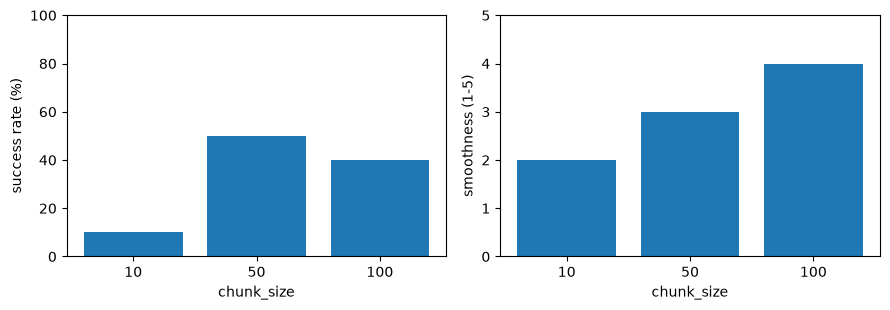

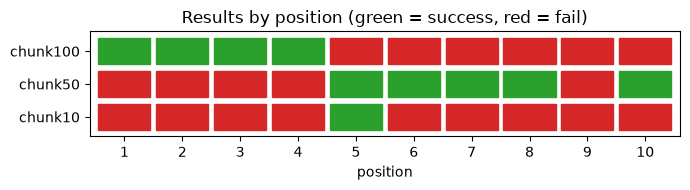

In [71]:
# 조건별 성공률과 부드러움
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
labels = [str(k) for k in summary.index]
axes[0].bar(labels, summary["success_rate"]); axes[0].set_ylim(0, 100)
axes[0].set_xlabel("chunk_size"); axes[0].set_ylabel("success rate (%)")
axes[1].bar(labels, summary["mean_smooth"]); axes[1].set_ylim(0, 5)
axes[1].set_xlabel("chunk_size"); axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()

# 위치별 성공/실패 (행 = chunk_size, 열 = 물체 위치)
fig, ax = plt.subplots(figsize=(7, 2.0))
for row, k in enumerate(CHUNK_SIZES):
    for r in results[k]:
        c = "tab:green" if r["success"] else ("tab:red" if r["success"] is False else "lightgray")
        ax.add_patch(plt.Rectangle((r["position"] - 0.45, row - 0.4), 0.9, 0.8, color=c))
ax.set_xlim(0.4, 10.6); ax.set_ylim(-0.6, len(CHUNK_SIZES) - 0.4)
ax.set_xticks(range(1, 11)); ax.set_yticks(range(len(CHUNK_SIZES)))
ax.set_yticklabels([f"chunk{k}" for k in CHUNK_SIZES]); ax.set_xlabel("position")
ax.set_title("Results by position (green = success, red = fail)")
plt.tight_layout(); plt.show()

### 3-4. 반응성 테스트
조건별로 3회씩 추가로 시도하되, 로봇이 물체를 향해 움직이기 시작한 직후 **물체를 약 5 cm 옮긴다.** 로봇이 새 위치를 따라가는지 관찰한다. (녹화는 선택, 성공률 집계에는 넣지 않음)

반응성 테스트는 녹화가 필요 없으므로 `--strategy.type=base`로 돌린다. `base`는 `--dataset.*` 대신 `--task="..."`와 `--duration=<초>`를 받는다.

`[작성]` 아래 `reactivity`를 채운다.

In [73]:
reactivity = {
    10:  [{"trial": i, "followed": i < 2, "note": "뚝뚝 끊기면서도 옮긴 위치로 방향을 바꿔 따라감" if i < 2 else "새 위치로 따라가지 못함"} for i in range(3)],
    50:  [{"trial": i, "followed": i < 1, "note": "chunk10보다 끊김이 덜한 상태로 따라감. 옮기는 타이밍이 중요해 보임" if i < 1 else "현재 청크를 끝까지 실행해 원래 방향으로 진행함"} for i in range(3)],
    100: [{"trial": i, "followed": False, "note": "부드럽지만 물체를 옮겨도 원래 위치로 가서 파지를 여러 번 시도함"} for i in range(3)],
}
react_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in reactivity.items()], ignore_index=True)
print(react_df.groupby("chunk_size")["followed"].apply(lambda s: f"{int(s.fillna(False).sum())}/3"))
react_df

chunk_size
10     2/3
50     1/3
100    0/3
Name: followed, dtype: object


,trial,followed,note,chunk_size
0,0,True,뚝뚝 끊기면서도 옮긴 위치로 방향을 바꿔 따라감,10
1,1,True,뚝뚝 끊기면서도 옮긴 위치로 방향을 바꿔 따라감,10
2,2,False,새 위치로 따라가지 못함,10
3,0,True,chunk10보다 끊김이 덜한 상태로 따라감. 옮기는 타이밍이 중요해 보임,50
4,1,False,현재 청크를 끝까지 실행해 원래 방향으로 진행함,50
5,2,False,현재 청크를 끝까지 실행해 원래 방향으로 진행함,50
6,0,False,부드럽지만 물체를 옮겨도 원래 위치로 가서 파지를 여러 번 시도함,100
7,1,False,부드럽지만 물체를 옮겨도 원래 위치로 가서 파지를 여러 번 시도함,100
8,2,False,부드럽지만 물체를 옮겨도 원래 위치로 가서 파지를 여러 번 시도함,100


### 3-5. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
chunk_size에 따른 **동작 차이가 잘 드러나는 장면**을 조건별로 하나씩 GIF로 만들어 `images/`에 올리고 아래에 삽입한다. (예: chunk10의 떨림, chunk100의 청크 경계 튐)

![chunk10](images/hw3_chunk10.gif)
![chunk50](images/hw3_chunk50.gif)
![chunk100](images/hw3_chunk100.gif)

## 4. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다. 가능하면 3절의 수치나 영상 장면을 근거로 든다.

**4-1. 가설 검증** — 성공률이 가장 높은 조건은 무엇이었는가? 1-2의 가설과 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.

성공률은 chunk50이 50%로 가장 높았고, chunk100이 40%, chunk10이 10%였다. 이는 1-2에서 세운 "chunk50이 정확성과 안정성의 균형으로 가장 높은 성공률을 보일 것"이라는 가설과 일치한다. chunk10은 큐브 쪽으로는 잘 따라갔지만 잦은 재계획으로 파지 단계에서 대부분 실패했고, chunk100은 부드럽게 움직였지만 파지 직전의 작은 위치 오차를 한 청크(약 3.3초) 동안 고치지 못해 놓치는 경우가 많았다. chunk50(약 1.67초)은 파지라는 연속 동작을 한 청크 안에서 처리할 만큼 길면서도, 오차를 비교적 빨리 수정할 만큼 짧아 두 문제를 모두 줄인 것으로 보인다. 다만 chunk50은 평가를 2회 진행해 30%와 50%로 변동이 있었으므로, 10회 평가만으로 chunk50과 chunk100의 차이를 확정하기는 어렵다.

**4-2. 짧은 청크의 문제** — chunk_size=10에서 관찰된 동작의 특징(떨림, 머뭇거림, 경로 이탈 등)을 compounding error 개념으로 설명하라.

chunk10은 약 0.33초마다 새 청크를 예측하므로, 한 에피소드(약 10초) 동안 30번 가까이 재계획한다. 재계획할 때마다 새 청크의 첫 동작이 이전 청크의 마지막 동작과 조금씩 어긋나, 이동 내내 뚝뚝 끊기고 떨리는 동작이 나타났다(smooth 평균 2). 이렇게 생긴 작은 오차는 다음 관측과 예측에 그대로 반영되어 청크마다 누적되며, 이것이 compounding error이다. 특히 정밀한 높이와 타이밍이 필요한 파지 단계에서 누적된 오차가 커져, 엉뚱한 곳을 집거나 그리퍼에 큐브가 걸려 밀려나는 실패가 반복되었고, 유일하게 성공한 회차에서도 떨림은 남아 있었다. 또한 CPU 추론 환경이라 재계획할 때마다 추론 지연이 생겨 끊김이 더 커졌을 가능성도 있다.

**4-3. 긴 청크의 대가** — chunk_size=100에서 청크가 바뀌는 순간 동작이 끊기거나 튀는 현상이 있었는가? 반응성 테스트 결과와 함께 설명하라.

chunk100은 세 조건 중 가장 부드러웠고(smooth 평균 4), 청크가 바뀌는 순간 크게 튀는 현상은 뚜렷하게 관찰되지 않았다. 대신 청크 경계는 동작이 "수정되는 시점"으로 드러났다. 파지 직전에 위치가 어긋나도 그 청크가 끝날 때까지 고치지 못하고 놓쳤고, 청크가 바뀐 뒤 새로 관측하고 나서야 다시 접근해 재시도하는 모습이 나타났다(GIF의 에피소드 1). 반응성 테스트에서도 chunk10은 2/3, chunk50은 1/3 따라갔지만, chunk100은 0/3으로 물체를 옮겨도 원래 위치로 가서 파지를 여러 번 시도했다. 즉, 긴 청크는 교정을 아예 막는 것이 아니라 교정 주기를 늦추며, chunk_size가 커질수록 부드러움을 얻는 대신 반응성을 잃는 trade-off가 있다.

**4-4. 오프라인 손실과 실제 성능** — 2-3의 `l1_loss`가 낮은 조건이 실로봇 성공률도 높았는가? 그렇지 않다면 이유는 무엇이라고 생각하는가?

학습 종료 시점의 l1_loss는 chunk10(0.0497) < chunk50(0.0647) < chunk100(0.0731) 순으로 chunk10이 가장 낮았지만, 실로봇 성공률은 chunk10이 10%로 가장 낮아 두 지표가 일치하지 않았다. l1_loss는 학습 데이터에서 한 청크 안의 행동을 얼마나 정확히 복원하는지만 측정하므로, 예측 구간이 짧은 chunk10이 유리할 수밖에 없다. 하지만 실제 실행에서는 정책이 낸 행동이 다음 관측을 바꾸고, 그 오차가 다음 예측에 누적되는 closed-loop 효과가 생기며, 오프라인 손실은 이를 반영하지 못한다. 따라서 chunk_size처럼 예측 구간 자체를 바꾸는 설정은 오프라인 손실만으로 비교할 수 없고, 실로봇 평가가 필요하다.

**4-5. 내 태스크에 맞는 chunk_size** — 본인 태스크의 길이와 정밀도 요구 수준을 고려할 때 어떤 chunk_size가 적합한가? 실험하지 않은 값(예: 30)을 제안해도 된다.

이 태스크는 시연 평균 길이가 약 10초(300프레임)이고, 큐브를 집는 단계에서 높이와 타이밍의 정밀도가 요구된다. 실험 결과 chunk10은 너무 자주 재계획해 파지가 불안정했고, chunk100은 교정이 늦어 위치 오차를 고치지 못했다. 따라서 파지 동작(약 1~2초)을 한 청크에 담을 수 있는 chunk_size 40~50 정도가 적합하다고 판단한다. 추가로 chunk50에서 n_action_steps를 25 정도로 줄여 더 자주 재계획하거나, chunk100에 temporal ensemble을 적용하는 방식도 부드러움과 반응성을 함께 높일 수 있는 대안이 될 것이다.

## 5. Temporal ensemble
chunk_size=100 정책을 그대로 두고 추론 방식만 바꿔, 매 스텝 추론하며 겹치는 예측을 가중 평균한다. 재학습은 필요 없다.

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=LeeJun12/act_pick-cube-2cam \
  --policy.n_action_steps=1 \
  --policy.temporal_ensemble_coeff=0.01 \
  --robot.type=so101_follower \
  --robot.port=COM4 \
  --robot.id=my_follower_arm \
  --robot.cameras="{ wrist: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}, overhead: {type: opencv, index_or_path: 1, width: 640, height: 480, fps: 30}}" \
  --dataset.repo_id=LeeJun12/rollout_act_pick-cube-2cam_chunk100_te \
  --dataset.single_task="Pick up the cube and put it in the box." \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=20 \
  --dataset.reset_time_s=15 \
  --dataset.private=false
```

> `lerobot-rollout`은 `--policy.path`로 불러온 설정 위에 `--policy.*` 값을 덮어쓴다. ACT는 `temporal_ensemble_coeff`를 설정하면 `n_action_steps=1`이어야 하며, 다른 값이면 시작할 때 오류를 낸다.

`[작성]` 3-1과 같은 위치·순서로 10회 평가하고 chunk100 결과와 성공률·부드러움·추론 지연을 비교한다. 3~5문장.

temporal ensemble(TE)을 적용한 chunk100은 성공률 0%, 부드러움 평균 1로, 일반 chunk100(성공률 40%, 부드러움 4)보다 크게 나빠졌다. 원인은 추론 지연이다. 일반 chunk100은 100스텝(약 3.3초)마다 한 번만 추론하지만, TE는 `n_action_steps=1`로 매 스텝 추론해야 한다. 이 평가 PC는 CPU 추론에 평균 252 ms(최대 403 ms)가 걸려, 목표 30 Hz(33.3 ms) 대신 약 3.9 Hz로만 동작했다(전체 777틱 중 100%가 시간 예산 초과). 그 결과 로봇이 매 스텝 멈췄다 움직이며 심하게 끊겼고, 20초 동안 실행한 동작이 약 78스텝(학습 데이터 기준 약 2.6초 분량)에 그쳐, 큐브 옆까지 접근하거나 큐브를 잡은 뒤에도 박스로 옮기기 전에 시간이 끝났다. TE는 겹치는 예측을 평균해 청크 경계의 튐을 줄이는 방법이지만, 추론 비용이 청크 방식보다 약 100배 커서 GPU처럼 매 스텝 실시간 추론이 가능한 환경에서만 효과를 기대할 수 있다.

In [77]:
# 5. Temporal ensemble 결과 입력
TE_EVAL_DATASET = f"{HF_USER}/rollout_act_pick-cube-2cam_chunk100_te_20261113_133650"   # [작성] Hub에 올라간 이름. 예: f"{HF_USER}/rollout_act_pick-cube_chunk100_te_20261102_100000"
te_results = [{"episode": i, "position": i + 1, "success": False, "smooth": 1, "note": "CPU 추론으로 약 3.9 Hz(목표 30 Hz)로만 동작해 매 스텝 끊김. 큐브 옆까지 접근해 집으려다 시간이 끝나거나, 큐브를 잡았지만 박스로 옮기기 전에 시간(20초)이 끝남"} for i in range(10)]   # [작성] results[100]과 같은 형식, 3-1과 같은 위치·순서

te_info = load_json(TE_EVAL_DATASET, "meta/info.json", repo_type="dataset") if TE_EVAL_DATASET else None
if te_info:
    n_ep = te_info.get("total_episodes")
    print(f"temporal ensemble 에피소드 {n_ep}개 ->", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

te_df = pd.DataFrame(te_results)
if te_df["success"].notna().all():
    print(f"temporal ensemble 성공률: {te_df['success'].astype(float).mean()*100:.0f}%, 부드러움 평균: {te_df['smooth'].mean():.1f}")
    print(f"chunk100 성공률        : {summary.loc[100, 'success_rate']:.0f}%, 부드러움 평균: {summary.loc[100, 'mean_smooth']:.1f}")
else:
    print("te_results를 실제 결과로 채울 것")

info.json:   0%|          | 0.00/3.81k [00:00<?, ?B/s]

temporal ensemble 에피소드 10개 -> 통과
temporal ensemble 성공률: 0%, 부드러움 평균: 1.0
chunk100 성공률        : 40%, 부드러움 평균: 4.0


C:\Users\SCPS\anaconda3\envs\lerobot\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\SCPS\.cache\huggingface\hub\datasets--LeeJun12--rollout_act_pick-cube-2cam_chunk100_te_20261113_133650. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [79]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in [*EVAL_DATASETS.values(), TE_EVAL_DATASET] if r),
}
for k in CHUNK_SIZES:
    check_items[f"chunk{k} 정책 업로드됨 (config.json, model.safetensors)"] = (
        file_ok(POLICY_REPOS[k], "config.json", "model") and file_ok(POLICY_REPOS[k], "model.safetensors", "model"))
    check_items[f"chunk{k} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"chunk{k} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"chunk{k} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
check_items["통제 변수 일치 (1-3)"] = all(cfg_df[c].nunique(dropna=False) == 1 for c in ["dataset", "steps", "batch_size", "seed"])
check_items["반응성 테스트 9회 입력"] = all(r["followed"] is not None for v in reactivity.values() for r in v)
check_items["temporal ensemble 평가 데이터셋 에피소드 10개"] = bool(te_info) and te_info.get("total_episodes") == 10
check_items["temporal ensemble 회차별 결과 10개 입력"] = all(r["success"] is not None for r in te_results)
check_items["temporal ensemble 실패 회차에 원인 기재"] = all(r["note"].strip() for r in te_results if r["success"] is False)

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 학습 데이터셋 접근 가능 (public)
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] chunk10 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk10 평가 데이터셋 에피소드 10개
[통과] chunk10 회차별 결과 10개 입력
[통과] chunk10 실패 회차에 원인 기재
[통과] chunk50 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk50 평가 데이터셋 에피소드 10개
[통과] chunk50 회차별 결과 10개 입력
[통과] chunk50 실패 회차에 원인 기재
[통과] chunk100 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk100 평가 데이터셋 에피소드 10개
[통과] chunk100 회차별 결과 10개 입력
[통과] chunk100 실패 회차에 원인 기재
[통과] 통제 변수 일치 (1-3)
[통과] 반응성 테스트 9회 입력
[통과] temporal ensemble 평가 데이터셋 에피소드 10개
[통과] temporal ensemble 회차별 결과 10개 입력
[통과] temporal ensemble 실패 회차에 원인 기재

모두 통과
